# Creditworthiness modelling: Baselines

In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, roc_auc_score, f1_score, 
                            classification_report, confusion_matrix, 
                            ConfusionMatrixDisplay)

<h2 style="color:orange">Load the data and split</h2>

In [128]:
# load data
path = "../data/processed-data/data_for_trees.csv"
df = pd.read_csv(path)

In [129]:
df = df.drop(columns=["Unnamed: 0"])
df

,person_home_ownership,person_emp_length_years,person_age_years,loan_intent,loan_grade,cb_person_default_on_file,loan_term_months,past_delinquencies,loan_int_rate,loan_percent_income,cb_person_cred_hist_length_years,loan_to_income_ratio,debt_to_income_ratio,open_accounts,credit_utilization_ratio,loan_status,lpi_lti_ratio,log_person_income_usd,log_loan_amount_usd,log_other_debt_usd
0,OWN,5.0,21,EDUCATION,B,N,36,3,11.14,0.10,2,0.104167,0.271646,10,0.585436,0,0.960000,9.169623,6.908755,7.383246
1,MORTGAGE,1.0,25,MEDICAL,C,N,36,0,12.87,0.57,3,0.572917,0.860469,14,0.750732,1,0.994909,9.169623,8.612685,7.923531
2,RENT,4.0,23,MEDICAL,C,N,12,0,15.23,0.53,2,0.534351,0.643592,15,0.379333,1,0.991857,11.089821,10.463132,8.875746
3,RENT,8.0,24,MEDICAL,C,Y,36,0,14.27,0.55,4,0.643382,0.930628,4,0.228103,1,0.854857,10.904138,10.463132,9.656765
4,OWN,2.0,21,VENTURE,A,N,36,0,7.14,0.25,2,0.252525,0.475933,10,0.827034,1,0.990000,9.200391,7.824446,7.701987
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32569,MORTGAGE,1.0,57,PERSONAL,C,N,36,1,13.16,0.11,30,0.109434,0.406065,11,0.892039,0,1.005172,10.878066,8.665786,9.662846
32570,MORTGAGE,4.0,54,PERSONAL,A,N,60,0,7.49,0.15,19,0.146875,0.394162,6,0.191486,0,1.021277,11.695255,9.777130,10.298074
32571,RENT,3.0,65,HOMEIMPROVEMENT,B,N,24,3,10.99,0.46,28,0.460526,0.738143,11,0.678980,1,0.998857,11.238502,10.463132,9.957022
32572,MORTGAGE,5.0,56,PERSONAL,B,N,36,1,11.48,0.10,26,0.100000,0.275744,3,0.223460,0,1.000000,11.918397,9.615872,10.179699


In [130]:
# X/y split
y = df.pop("loan_status")
X = df.copy()

In [131]:
# train-test stratified split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

## <font color="orange"> Dummy Classifiers </font>

In [132]:
dummy_clfs = {
    "dummy_most_frequent": DummyClassifier(strategy="most_frequent"),
    "dummy_stratified": DummyClassifier(strategy="stratified", random_state=142),
    "dummy_constant": DummyClassifier(strategy="constant", constant=1),
}

In [133]:
for name, clf in dummy_clfs.items():
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)
    positive_idx = list(clf.classes_).index(1)
    y_score = clf.predict_proba(X_test)[:, positive_idx]

    print(f"\n{name}")
    print(f"Average precision: {average_precision_score(y_test, y_score):.4f}")
    print(f"Balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
    print(f"ROC AUC: {roc_auc_score(y_test, y_score):.4f}")
    print(f"F1 score: {f1_score(y_test, y_pred, zero_division=0):.4f}")
    print(classification_report(y_test, y_pred, digits=3, zero_division=0))



dummy_most_frequent
Average precision: 0.2181
Balanced accuracy: 0.5000
ROC AUC: 0.5000
F1 score: 0.0000
              precision    recall  f1-score   support

           0      0.782     1.000     0.878      5094
           1      0.000     0.000     0.000      1421

    accuracy                          0.782      6515
   macro avg      0.391     0.500     0.439      6515
weighted avg      0.611     0.782     0.686      6515


dummy_stratified
Average precision: 0.2164
Balanced accuracy: 0.4948
ROC AUC: 0.4948
F1 score: 0.2080
              precision    recall  f1-score   support

           0      0.780     0.783     0.782      5094
           1      0.210     0.206     0.208      1421

    accuracy                          0.658      6515
   macro avg      0.495     0.495     0.495      6515
weighted avg      0.655     0.658     0.656      6515


dummy_constant
Average precision: 0.2181
Balanced accuracy: 0.5000
ROC AUC: 0.5000
F1 score: 0.3581
              precision    recall  f

## <font color="orange"> Pipelines for Decision Tree baseline </font>

In [134]:
# feature division 
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
ohe_features = X_train.select_dtypes(exclude=np.number).columns.drop("loan_grade").tolist()
ordinal_feature = ["loan_grade"]

# impute pipeline
impute_preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("scaler", StandardScaler()),
            ("imputer", KNNImputer(n_neighbors=5, weights="distance", add_indicator=True)), # default k=5
        ]), numeric_features),
        ("ordinal", Pipeline([
            ("encoder", OrdinalEncoder(
                categories=[["A", "B", "C", "D", "E", "F", "G"]],
                handle_unknown="use_encoded_value",
                unknown_value=-1,
            )),
        ]), ordinal_feature),
        ("ohe", Pipeline([
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]), ohe_features),
    ],
    remainder="drop",
)

# non-impute pipeline (using built-in)
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", numeric_features),
        ("ordinal", Pipeline([
            ("encoder", OrdinalEncoder(
                categories=[["A", "B", "C", "D", "E", "F", "G"]],
                handle_unknown="use_encoded_value",
                unknown_value=-1,
            )),
        ]), ordinal_feature),
        ("ohe", Pipeline([
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]), ohe_features),
    ],
    remainder="drop",
)


In [135]:
# pipeline with kNN impute
impute_model = Pipeline([
    ("preprocessor", impute_preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=5, 
                                        min_samples_leaf=20, 
                                        class_weight="balanced", 
                                        random_state=42)
    ),
])

impute_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['person_home_ownership','person_emp_length_years','person_age_years',..., 'log_person_income_usd','log_loan_amount_usd','log_other_debt_usd']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcol

In [136]:
# pipeline without kNN impute
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=5, 
                                        min_samples_leaf=20, 
                                        class_weight="balanced", 
                                        random_state=42)
    ),
])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['person_home_ownership','person_emp_length_years','person_age_years',..., 'log_person_income_usd','log_loan_amount_usd','log_other_debt_usd']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('ordinal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcol

In [137]:
def ap_with_ci(y_true, proba, n_boot=1000, seed=42):
    """ helper to calculate average precision with 95% CI
    """
    y = np.asarray(y_true)
    p = np.asarray(proba)
    rng = np.random.default_rng(seed)
    scores = [
        average_precision_score(y[b], p[b])
        for b in (rng.integers(0, len(y), len(y)) for _ in range(n_boot))
    ]
    lo, hi = np.percentile(scores, [2.5, 97.5])
    return average_precision_score(y, p), lo, hi

In [138]:
def report(clf_model):
    """ Helper to compute and report metrics """
    positive_idx = list(clf_model.classes_).index(1)
    rows = {}
    clf_reports = []
    for sname, X_s, y_s in [
        ("Training", X_train, y_train),
        ("Evaluation", X_test, y_test),
    ]:
        y_pred = clf_model.predict(X_s)   # threshold = 0.5
        score = clf_model.predict_proba(X_s)[:, positive_idx]
        rows[sname] = {
            "prevalence": np.mean(y_s),
            "PR-AUC (AP)": average_precision_score(y_s, score),
            "ROC-AUC": roc_auc_score(y_s, score),
            "balanced acc": balanced_accuracy_score(y_s, y_pred),
            "F1 (pos)": f1_score(y_s, y_pred, zero_division=0),
        }
        clf_reports.append(classification_report(y_s, y_pred, digits=3, zero_division=0))
        if sname == "Evaluation":
            ap, lo, hi = ap_with_ci(y_s, score)
            print(f"Test PR-AUC: {ap:.3f} [{lo:.3f}, {hi:.3f}]")
            print("Confusion matrix (rows = true, cols = predicted):")
            ConfusionMatrixDisplay.from_predictions(
                y_s, 
                y_pred, 
                cmap=plt.cm.Blues
            )
            plt.show()
    return rows, clf_reports

Test PR-AUC: 0.804 [0.786, 0.821]
Confusion matrix (rows = true, cols = predicted):


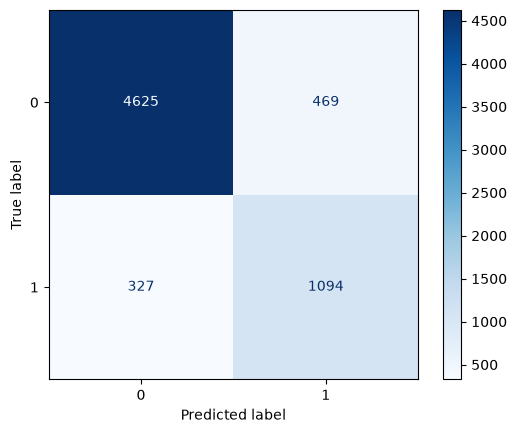

,prevalence,PR-AUC (AP),ROC-AUC,balanced acc,F1 (pos)
Training,0.2182,0.8172,0.8935,0.8480,0.7437
Evaluation,0.2181,0.8041,0.8803,0.8389,0.7332


Set train
              precision    recall  f1-score   support

           0      0.939     0.907     0.923     20373
           1      0.703     0.789     0.744      5686

    accuracy                          0.881     26059
   macro avg      0.821     0.848     0.833     26059
weighted avg      0.888     0.881     0.884     26059

Set test
              precision    recall  f1-score   support

           0      0.934     0.908     0.921      5094
           1      0.700     0.770     0.733      1421

    accuracy                          0.878      6515
   macro avg      0.817     0.839     0.827      6515
weighted avg      0.883     0.878     0.880      6515



In [139]:
# reports for impute_model
rows, rep = report(impute_model)
results = pd.DataFrame(rows).T.round(4)
display(results)

for i, z in enumerate(["train", "test"]):
    print(f"Set {z}")
    print(rep[i])

Test PR-AUC: 0.804 [0.785, 0.820]
Confusion matrix (rows = true, cols = predicted):


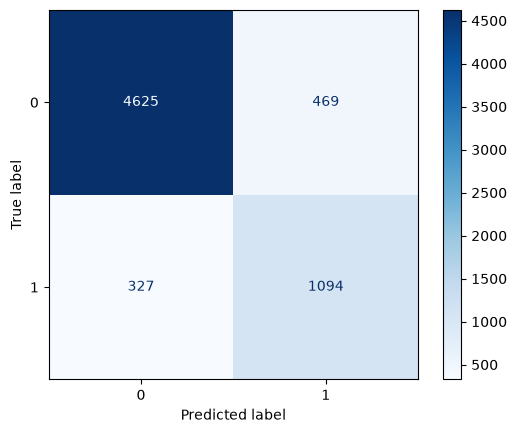

,prevalence,PR-AUC (AP),ROC-AUC,balanced acc,F1 (pos)
Training,0.2182,0.8180,0.8936,0.8480,0.7437
Evaluation,0.2181,0.8036,0.8803,0.8389,0.7332


Set train
              precision    recall  f1-score   support

           0      0.939     0.907     0.923     20373
           1      0.703     0.789     0.744      5686

    accuracy                          0.881     26059
   macro avg      0.821     0.848     0.833     26059
weighted avg      0.888     0.881     0.884     26059

Set test
              precision    recall  f1-score   support

           0      0.934     0.908     0.921      5094
           1      0.700     0.770     0.733      1421

    accuracy                          0.878      6515
   macro avg      0.817     0.839     0.827      6515
weighted avg      0.883     0.878     0.880      6515



In [140]:
# reports for model without knn impute
rows, rep = report(model)
results = pd.DataFrame(rows).T.round(4)
display(results)

for i, z in enumerate(["train", "test"]):
    print(f"Set {z}")
    print(rep[i])